# Assignment 2: Which song fits this playlist?
### Choosing between two candidates using five example songs

**Research question.** Can audio similarity identify an observed playlist member, and how much do artist identity and artist co-occurrence add?

This notebook combines the complete benchmark in `assignment_2.ipynb` with the extended study in `workbook.ipynb`. It follows the assignment's five sections: **1. Predictive task; 2. Exploratory analysis, data collection and preprocessing; 3. Modeling; 4. Evaluation; 5. Discussion of related work.** Each section includes the relevant context, discussion and implementation. Both implementations, their visualizations, model selection, subgroup checks and examples are retained; the second implementation also checks agreement with the first.

**Main findings.** The original audio-plus-artist logistic model achieves **74.7%** accuracy on 1,000 choices from 100 held-out playlists. The extended hybrid adds artist co-occurrence and achieves **86.2%**. On 824 matched choices with same-artist alternatives it achieves **53.5%**. The alternative's identity changes what accuracy measures.

**Reproduce.** Install `requirements.txt`, keep `data/songs620.csv` here (or place `songs620.csv` beside this notebook), or set `SONGS620_PATH`, then run cells in order from this folder. The extension checks the original file's SHA-256. Saved tables and figures below make the results readable without rerunning. The original benchmark also writes its experiment artifacts to `output/playlist_matching/` when executed.

The original study and its extended analysis are successive stages of this project. Their common benchmark is a replication check, rather than independent evidence from another dataset. This deliverable is the notebook only.

## 1. Predictive task

### 1.1 Benchmark task and validity

For each eligible playlist, sample six **distinct** songs without replacement.
Five form the visible context, and the sixth is the hidden member. Sample a second
candidate uniformly from all distinct catalogue tracks absent from the **entire**
playlist, and randomly place the hidden member in candidate A or B. Predict which
candidate is the member. Order and original track positions play no role.

**Example:** five songs from a playlist → candidate A versus candidate B → choose A or B.
The label is observed playlist membership, not a judgment that the other song sounds bad.

**Evaluation plan:** fix seed 42 and split whole playlists 80%/10%/10% into training,
validation, and test before making examples. Draw ten examples per eligible playlist
in each split. Examples can reuse songs within a playlist, so uncertainty is measured
by resampling **playlists**, not by treating every query as independent.

Choose regularization and the primary learned model on validation accuracy, freeze
these choices, then evaluate test accuracy. Ties get half credit: the expected result
of a fair coin flip. All eligible playlists supply ten queries, giving them equal weight.

**What success means:** accuracy above the 50% random baseline, with a playlist-bootstrap
interval and paired comparisons against audio similarity. A higher score alone does
not establish that learning improves on a simple rule.

**Scope:** this is a known-catalogue, new-playlist task. Static metadata may be looked up
for every candidate. Playlist-derived popularity and fitted preprocessing use training
playlists only. Track overlap between splits is allowed; playlist overlap is not.

### 1.2 Extension and matched diagnostic
Given five distinct tracks sampled from one playlist, choose between two other tracks. One is a hidden member. The other is drawn uniformly from recordings absent from the entire playlist. Either candidate can occupy the left slot. Positions and play order play no role.

**Unit of evaluation.** Each eligible playlist contributes ten choices. Accuracy counts a correct choice as 1 and a tied score as ½, the expected credit for a fair coin. Random guessing earns 50%. Each error costs the same and exactly one candidate is relevant, so two-choice accuracy directly answers the question. Full-catalog recall, skips and listener satisfaction would require different experiments.

**Decision rule.** Select the model and tuning parameters on validation accuracy using uniform alternatives. Keep those choices fixed on test. Compare every method on identical candidate pairs, including a harder follow-up that holds the candidate artist constant. A playlist-level paired interval measures how consistently a gain occurs across playlists.

### 1.3 Environment and reproducibility
The shared imports support both complete implementations. Fixed seeds specify playlist splits, query sampling and uncertainty estimates.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
from pathlib import Path

ROOT = Path.cwd()
OUT = ROOT / 'output' / 'playlist_matching'
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'tmp' / 'matplotlib'))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
CONTEXT_SIZE = 5
QUERIES_PER_PLAYLIST = 10
C_GRID = [0.01, 0.1, 1.0, 10.0]
AUDIO = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
FEATURES = ['closeness_' + x for x in AUDIO] + ['nearest_audio', 'artist_fraction']
MODEL_COLUMNS = {'Logistic: audio': list(range(11)),
                 'Logistic: audio + artist': list(range(12))}



from IPython.display import display, Image, Markdown
_thread_limit = threadpool_limits(limits=4)

In [2]:
from pathlib import Path
import hashlib, os, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.sparse import csr_matrix
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import CategoricalNB
from IPython.display import display, Markdown
%matplotlib inline
plt.rcParams.update({'figure.dpi': 112, 'axes.spines.top': False, 'axes.spines.right': False})
teal, blue, gold = '#14776e', '#36597e', '#b36c27'
pd.options.display.float_format = '{:,.3f}'.format
paths = [Path('songs620.csv'), Path('data/songs620.csv'), Path.home()/'Desktop'/'songs620.csv']
if 'SONGS620_PATH' in os.environ:
    paths = [Path(os.environ['SONGS620_PATH']).expanduser()]
path = next((p for p in paths if p.is_file()), None)
if path is None:
    raise FileNotFoundError('Place songs620.csv beside this notebook, or set SONGS620_PATH.')
digest = hashlib.sha256(path.read_bytes()).hexdigest()
assert digest == '11533e4997668e7791c093bbcc63fb20ed820e8c4bbd80b7026fedaf1fb8d946'
print('Input SHA-256', digest)
print('Python', platform.python_version(), '| NumPy', np.__version__, '| pandas', pd.__version__,
      '| SciPy', scipy.__version__, '| scikit-learn', sklearn.__version__)

Input SHA-256 11533e4997668e7791c093bbcc63fb20ed820e8c4bbd80b7026fedaf1fb8d946
Python 3.14.4 | NumPy 2.5.5 | pandas 3.1.1 | SciPy 1.18.1 | scikit-learn 1.9.1


## 2. Exploratory analysis, data collection and preprocessing

### 2.1 Data definition and benchmark preparation

The local `songs620.csv` contains playlist IDs, track and artist URIs, positions,
and numeric audio descriptors. Playlist membership supplies labels; danceability,
energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence,
tempo, and duration supply audio predictors. We do not fetch Spotify URLs.

Spotify's [Million Playlist Dataset introduction](https://engineering.atspotify.com/2018/05/introducing-the-million-playlist-dataset-and-recsys-challenge-2018)
describes a public-playlist research resource. The local CSV has a compatible schema,
but the original benchmark did not verify its exact sampling and audio-enrichment history. The extended notebook records a more specific source attribution below. A schema or checksum alone does not establish the complete collection history. It has no
listener IDs, satisfaction labels, or timestamps for a chronological split.

Deduplicate `(playlist, track)` memberships so a repeated recording does not count as
two distinct songs. Identify recordings by URI, not name. Reject missing or conflicting
modeled metadata and nonfinite audio values. Playlists with fewer than six distinct
tracks stay in their original split but cannot supply examples.

Log-transform tempo and duration using `log1p`, then standardize the ten audio features
using **distinct tracks in training playlists only**. These transformations are fitted
once and applied unchanged to validation and test candidates. Popularity counts the
number of training playlists containing each track.

In [3]:
def find_dataset():
    override = os.environ.get('SONGS620_PATH')
    if override:
        path = Path(override).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'SONGS620_PATH does not exist: {path}')
        return path
    for path in [ROOT / 'songs620.csv', ROOT / 'data' / 'songs620.csv']:
        if path.is_file():
            return path
    raise FileNotFoundError('Put songs620.csv in data/ or set SONGS620_PATH.')


def prepare_data():
    OUT.mkdir(parents=True, exist_ok=True)
    path = find_dataset()
    raw = pd.read_csv(path)
    required = ['pid', 'track_uri', 'artist_uri'] + AUDIO
    if raw[required].isna().any().any():
        raise ValueError('Missing modeled metadata requires an explicit handling rule.')
    if not np.isfinite(raw[AUDIO].to_numpy()).all():
        raise ValueError('Nonfinite audio values.')
    metadata = raw.groupby('track_uri')[['artist_uri'] + AUDIO].nunique()
    if metadata.gt(1).any().any():
        raise ValueError('Conflicting metadata for a recording.')
    tracks = raw.drop_duplicates('track_uri').sort_values('track_uri').reset_index(drop=True)
    lookup = dict(zip(tracks.track_uri, tracks.index))
    raw['item'] = raw.track_uri.map(lookup)
    members = {int(pid): np.sort(g.item.unique()) for pid, g in raw.groupby('pid')}
    pids = np.random.default_rng(SEED).permutation(sorted(members))
    n_train, n_val = int(.8 * len(pids)), int(.1 * len(pids))
    split = {'train': pids[:n_train], 'validation': pids[n_train:n_train+n_val],
             'test': pids[n_train+n_val:]}
    train_items = np.unique(np.concatenate([members[int(p)] for p in split['train']]))
    # Each distinct training track contributes once to the audio scaler.
    audio = tracks[AUDIO].to_numpy(dtype=float)
    for col in ['tempo', 'duration_ms']:
        j = AUDIO.index(col)
        if (audio[:, j] < 0).any():
            raise ValueError(f'Negative {col}.')
        audio[:, j] = np.log1p(audio[:, j])
    scaler = StandardScaler().fit(audio[train_items])
    z = scaler.transform(audio)
    pop = np.zeros(len(tracks), dtype=int)
    for pid in split['train']:
        pop[members[int(pid)]] += 1
    split_frame = pd.DataFrame([(int(p), s) for s, ids in split.items() for p in ids],
                               columns=['pid', 'split'])
    split_frame.to_csv(OUT / 'playlist_split.csv', index=False)
    tracks.assign(item=tracks.index).to_csv(OUT / 'catalogue.csv', index=False)
    summary = {'rows': len(raw), 'unique_memberships': sum(map(len, members.values())),
               'tracks': len(tracks), 'playlists': len(members),
               'artists': int(tracks.artist_uri.nunique()),
               'repeated_memberships_removed': int(raw.duplicated(['pid', 'item']).sum()),
               'singleton_tracks': int(raw.groupby('item').pid.nunique().eq(1).sum()),
               'eligible_playlists': {s: sum(len(members[int(p)]) >= 6 for p in ids)
                                      for s, ids in split.items()},
               'split_playlists': {s: len(ids) for s, ids in split.items()},
               'dataset_sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
    return dict(raw=raw, tracks=tracks, members=members, split=split, z=z,
                artists=tracks.artist_uri.to_numpy(), pop=pop, train_items=train_items,
                audio_scaler=scaler, summary=summary)


def make_queries(members, pids, catalogue_size, seed, per_playlist=QUERIES_PER_PLAYLIST):
    rng = np.random.default_rng(seed)
    rows = []
    for pid in sorted(pids):
        playlist = members[int(pid)]
        if len(playlist) < CONTEXT_SIZE + 1:
            continue
        outsiders = np.setdiff1d(np.arange(catalogue_size), playlist, assume_unique=True)
        if not len(outsiders):
            raise ValueError('No nonmember candidates.')
        for q in range(per_playlist):
            six = rng.choice(playlist, CONTEXT_SIZE + 1, replace=False)
            positive, negative = int(six[-1]), int(rng.choice(outsiders))
            label = int(rng.integers(2))  # 1 means candidate A is the member.
            a, b = (positive, negative) if label else (negative, positive)
            rows.append([int(pid), q, *map(int, six[:5]), a, b, label])
    return pd.DataFrame(rows, columns=['pid', 'query', 'h0', 'h1', 'h2', 'h3', 'h4',
                                       'candidate_a', 'candidate_b', 'label'])

In [4]:
data = prepare_data()
display(pd.Series(data['summary']).drop(['eligible_playlists', 'split_playlists', 'dataset_sha256']).to_frame('value'))
display(pd.DataFrame({'all_playlists': data['summary']['split_playlists'],
                      'eligible_playlists': data['summary']['eligible_playlists']}))
display(data['tracks'][['track_name', 'artist_name'] + AUDIO].head())

,value
rows,66263
unique_memberships,65409
tracks,36203
playlists,1000
artists,9963
repeated_memberships_removed,854
singleton_tracks,26901


,all_playlists,eligible_playlists
train,800,795
validation,100,98
test,100,100


,track_name,artist_name,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,Still Got Time,ZAYN,0.748,0.627,-6.029,0.064,0.131,0.000,0.085,0.524,120.963,188491
1,Yee - Original Mix,Deorro,0.732,0.989,-4.172,0.048,0.102,0.748,0.055,0.684,127.984,210000
2,Live and Let Live,Red Allen & The Kentuckians,0.445,0.514,-12.202,0.031,0.495,0.000,0.345,0.818,115.357,167653
3,I've Failed You,Kittie,0.511,0.958,-3.688,0.038,0.000,0.000,0.089,0.678,102.015,131853
4,Heart and Soul,Kevin Jonas,0.605,0.846,-4.581,0.078,0.001,0.000,0.053,0.764,132.997,177773


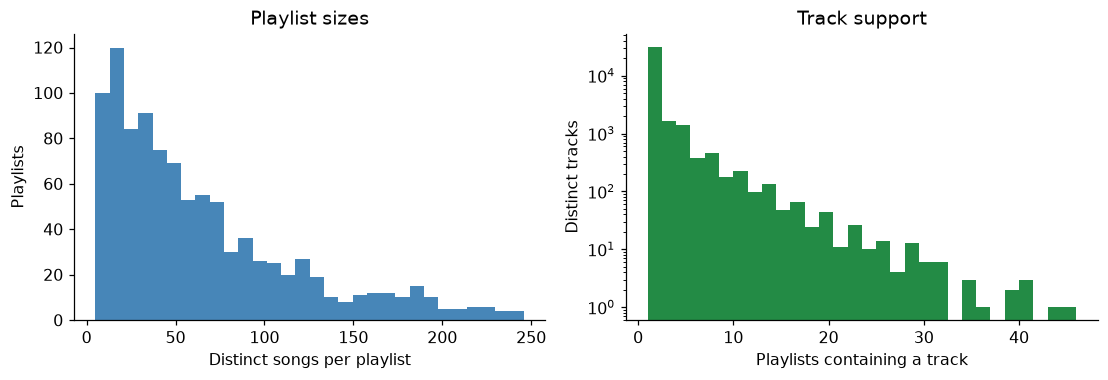

74.3% of tracks occur in just one playlist.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist([len(v) for v in data['members'].values()], bins=30, color='#4786b8')
axes[0].set(xlabel='Distinct songs per playlist', ylabel='Playlists', title='Playlist sizes')
counts = data['raw'].groupby('item').pid.nunique()
axes[1].hist(counts, bins=30, color='#238b45')
axes[1].set(xlabel='Playlists containing a track', ylabel='Distinct tracks', title='Track support')
axes[1].set_yscale('log')
fig.tight_layout()
display(fig)
plt.close(fig)
print(f"{data['summary']['singleton_tracks'] / len(data['tracks']):.1%} of tracks occur in just one playlist.")

Many songs appear in only one playlist, limiting identity-based retrieval. Static audio
features still describe these songs. Playlist matching between two candidates reduces
the search burden while retaining an observed behavioral label.

The [earlier Spotify project presentation](https://docs.google.com/presentation/d/1er6tXVBatdB-UJQ5t9p4c7T3HA4U4P42Cuk8XslenCA/edit)
in Google Drive motivates grouping and recommending songs using their features. It is
background context, not an additional source of training labels or measured accuracy.

### 2.2 Source attribution and extended exploration
The source `workbook.ipynb` identifies the file as a byte-for-byte match to the published AC209A Group 137 slice. Its attribution and source links are retained here; the code verifies the local input against that notebook's recorded SHA-256. The remote file was not independently rechecked during this synthesis. The group describes enriching Million Playlist Dataset tracks with Spotify audio features. Spotify collected public, user-created US playlists from 2010–2017. This single slice has no individual listener judgments, curator IDs or creation dates for a chronological evaluation. [Upstream Spotify collection](https://engineering.atspotify.com/2018/05/introducing-the-million-playlist-dataset-and-recsys-challenge-2018) · [Enrichment project](https://suton5.github.io/recsys137/) · [Published CSV](https://github.com/suton5/recsys137/blob/master/test_data/songs620.csv)

A recording URI identifies a track across playlists. Collapse repeated occurrences within each playlist because the label is membership. Split playlist IDs first. Static artist and audio metadata are available across the snapshot. Fit scaling and estimate interaction history from training playlists. A track shared across splits is legitimate in this known-catalog experiment.

In [6]:
audio_cols = ['danceability','energy','loudness','speechiness','acousticness',
              'instrumentalness','liveness','valence','tempo','duration_ms']
df = pd.read_csv(path)
required = ['pid','track_uri','artist_uri',*audio_cols]
assert df[required].notna().all().all() and np.isfinite(df[audio_cols]).all().all()
assert df.groupby('track_uri')[['artist_uri',*audio_cols]].nunique().le(1).all().all()
catalog = df.drop_duplicates('track_uri').set_index('track_uri').sort_index()
df['item'] = catalog.index.get_indexer(df.track_uri)
members = {p: np.unique(g.item) for p,g in df.groupby('pid')}
artist = pd.factorize(catalog.artist_uri)[0]
items = np.arange(len(catalog))
ids = np.random.default_rng(42).permutation(sorted(members))
train, valid, test = ids[:800], ids[800:900], ids[900:]
assert len(ids)==1000 and len(set(train)|set(valid)|set(test))==sum(map(len,[train,valid,test]))
train_counts = np.bincount(np.concatenate([members[p] for p in train]), minlength=len(items))
audio = catalog[audio_cols].to_numpy().copy()
audio[:,-2:] = np.log1p(audio[:,-2:])  # Same tempo/duration transformation as the reference.
z = StandardScaler().fit(audio[train_counts>0]).transform(audio)
split_rows = []
for label, group in [('Train',train),('Validation',valid),('Test',test)]:
    eligible = sum(len(members[p])>=6 for p in group)
    split_rows.append([label,len(group),eligible,eligible*10])
display(pd.DataFrame(split_rows,columns=['Split','Playlists','Eligible','Queries']).set_index('Split'))
print(f'{len(df):,} placements · {len(catalog):,} recordings · {len(set(artist)):,} artists · '
      f'{df.duplicated(["pid","item"]).sum():,} repeated memberships collapsed')

,Playlists,Eligible,Queries
Split,,,
Train,800,795,7950
Validation,100,98,980
Test,100,100,1000


66,263 placements · 36,203 recordings · 9,963 artists · 854 repeated memberships collapsed


In [7]:
context_cols = [f'seed{i}' for i in range(1,6)]
def sample_queries(group, seed):
    rng = np.random.default_rng(seed)
    records = []
    for pid in sorted(group):
        songs = members[pid]
        if len(songs)<6:
            continue
        outside = np.setdiff1d(items,songs,assume_unique=True)
        for j in range(10):
            six = rng.choice(songs,6,replace=False)
            other = rng.choice(outside)
            side = int(rng.integers(2))
            a,b = (six[-1],other) if side else (other,six[-1])
            records.append([pid,j,*six[:5],a,b,side])
    return pd.DataFrame(records,columns=['pid','query',*context_cols,'a','b','y'])

training = sample_queries(train,43)
validation = sample_queries(valid,44)
def check_queries(q):
    for pid,g in q.groupby('pid'):
        context = g[context_cols].to_numpy()
        pos = np.where(g.y,g.a,g.b)
        neg = np.where(g.y,g.b,g.a)
        assert (np.diff(np.sort(context),axis=1)>0).all() and (pos[:,None]!=context).all()
        assert np.isin(context,members[pid]).all() and np.isin(pos,members[pid]).all()
        assert not np.isin(neg,members[pid]).any()
check_queries(training)
check_queries(validation)

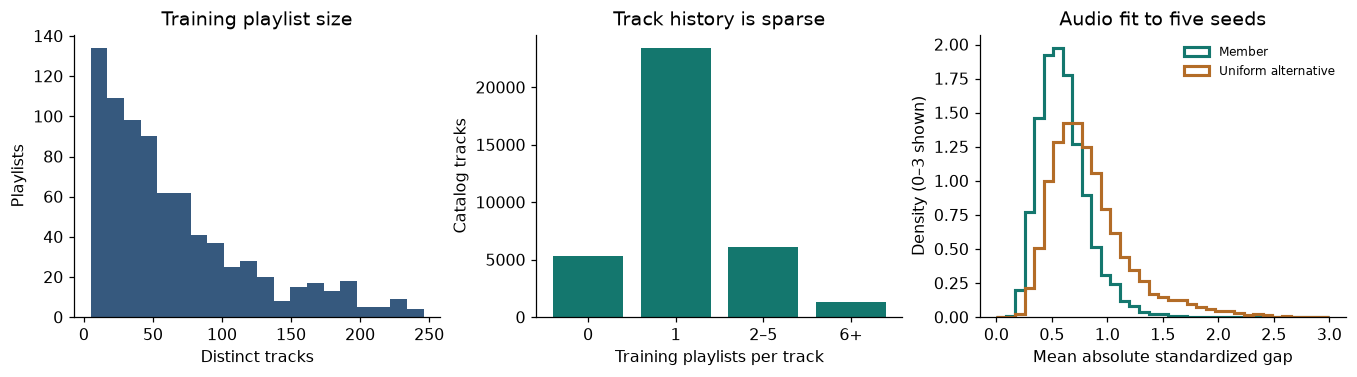

28,779 catalog songs have history in at most one training playlist.
Artist appears among seeds: 17.0% for members, 0.2% for alternatives.
Median audio gap: member 0.58, alternative 0.77.


In [8]:
q = training
seeds = q[context_cols].to_numpy()
pos, neg = np.where(q.y,q.a,q.b), np.where(q.y,q.b,q.a)
fig, ax = plt.subplots(1,3,figsize=(12,3.25),layout='constrained')
ax[0].hist([len(members[p]) for p in train],bins=20,color=blue)
ax[0].set(title='Training playlist size',xlabel='Distinct tracks',ylabel='Playlists')
counts = [sum(train_counts==0),sum(train_counts==1),sum((train_counts>=2)&(train_counts<=5)),sum(train_counts>=6)]
ax[1].bar(['0','1','2–5','6+'],counts,color=teal)
ax[1].set(title='Track history is sparse',xlabel='Training playlists per track',ylabel='Catalog tracks')
center = z[seeds].mean(axis=1)
bins = np.linspace(0,3,36)
for candidates,label,col in [(pos,'Member',teal),(neg,'Uniform alternative',gold)]:
    distance = np.abs(z[candidates]-center).mean(axis=1)
    ax[2].hist(distance,bins=bins,density=True,histtype='step',lw=2,color=col,label=label)
ax[2].legend(frameon=False,fontsize=8)
ax[2].set(title='Audio fit to five seeds',xlabel='Mean absolute standardized gap',ylabel='Density (0–3 shown)')
plt.show()
def artist_overlap(candidates):
    return (artist[candidates,None]==artist[seeds]).any(axis=1).mean()
print(f'{sum(train_counts<=1):,} catalog songs have history in at most one training playlist.')
print(f'Artist appears among seeds: {artist_overlap(pos):.1%} for members, {artist_overlap(neg):.1%} for alternatives.')
print(f'Median audio gap: member {np.median(abs(z[pos]-center).mean(1)):.2f}, alternative {np.median(abs(z[neg]-center).mean(1)):.2f}.')

The first panel shows why each playlist gets ten queries. Sampling every possible group would give long playlists much greater influence. The second motivates pooling history at artist level. The overlapping audio distributions in the third explain both the value and the limits of a distance-only rule. A random outsider can differ on sound and artist at the same time. The harder test in Section 4 removes one of these shortcuts.

## 3. Modeling

### 3.1 Original content and artist models

Each model gives candidate A and B a compatibility score and chooses the higher one.

| Model | Compatibility rule |
|---|---|
| Random | Fair coin; expected accuracy 50% |
| Popularity | Number of training playlists containing the candidate |
| Artist overlap | Fraction of the five context songs sharing the candidate's artist |
| Audio distance | Negative sum of absolute standardized differences from the context's mean audio vector |
| Logistic: audio | Learn weights for ten per-feature closeness values and distance to the nearest context song |
| Logistic: audio + artist | Add the artist-overlap feature to the same learned model |

For each audio dimension, closeness is the negative absolute difference between the
candidate and the five-song mean. Nearest-song closeness is negative Euclidean distance
to the closest of the five songs. Higher values mean greater similarity.

**Simple explanation of logistic regression:** learn how much weight to give similarities
such as energy, tempo, and artist overlap when choosing between the two songs.

Subtract B's features from A's features, then fit logistic regression to predict whether
A is the member. Include each training pair and its swapped version with the opposite
label; omit the intercept. Reversing A and B therefore reverses the score. Scale feature
differences using training examples only. There are no track-ID, album-ID, playlist-ID,
or co-occurrence predictors, so a training playlist cannot leak its membership through
its own historical counts into a learned feature.

Test C ∈ {0.01, 0.1, 1, 10} for each learned model. Choose the highest validation
accuracy, breaking ties toward smaller C. Choose the primary learned model by validation
accuracy, breaking ties toward fewer features. Keep the original training fit after
selection. Coefficients describe associations under this sampling scheme, not causes.

In [9]:
def candidate_features(data, contexts, candidates):
    seeds = data['z'][contexts]
    candidate = data['z'][candidates]
    centroid = seeds.mean(axis=1)
    closeness = -np.abs(candidate - centroid)
    nearest = -np.sqrt(((seeds - candidate[:, None, :]) ** 2).sum(axis=2)).min(axis=1)
    artist_fraction = (data['artists'][contexts] == data['artists'][candidates, None]).mean(axis=1)
    return np.column_stack([closeness, nearest, artist_fraction])


def query_features(data, queries):
    contexts = queries[[f'h{i}' for i in range(5)]].to_numpy(dtype=int)
    a = candidate_features(data, contexts, queries.candidate_a.to_numpy())
    b = candidate_features(data, contexts, queries.candidate_b.to_numpy())
    return a - b


def baseline_scores(data, queries, delta):
    # Greater is always stronger evidence for candidate A.
    return {'Random (expected)': np.zeros(len(queries)),
            'Popularity': data['pop'][queries.candidate_a] - data['pop'][queries.candidate_b],
            'Artist overlap': delta[:, -1],
            'Audio distance': delta[:, :10].sum(axis=1)}


def correct_credit(scores, labels):
    """Fair random tie-breaking has expected correctness 0.5."""
    scores, labels = np.asarray(scores), np.asarray(labels)
    return np.where(scores == 0, .5, (scores > 0) == labels).astype(float)


def fit_models(train_x, train_y, val_x, val_y):
    fitted, grid, selected = {}, [], {}
    for name, columns in MODEL_COLUMNS.items():
        # Mirrored pairs prevent candidate-position bias and enforce swap symmetry.
        x = np.vstack([train_x[:, columns], -train_x[:, columns]])
        y = np.concatenate([train_y, 1 - train_y])
        options = []
        for c in C_GRID:
            model = make_pipeline(StandardScaler(with_mean=False),
                                  LogisticRegression(C=c, fit_intercept=False, max_iter=2000))
            model.fit(x, y)
            accuracy = correct_credit(model.decision_function(val_x[:, columns]), val_y).mean()
            grid.append({'model': name, 'C': c, 'validation_accuracy': accuracy})
            options.append((accuracy, -c, model))
        accuracy, neg_c, model = max(options, key=lambda v: (v[0], v[1]))
        fitted[name] = model
        selected[name] = {'C': -neg_c, 'validation_accuracy': accuracy}
    primary = max(selected, key=lambda name: (selected[name]['validation_accuracy'],
                                             -len(MODEL_COLUMNS[name])))
    return fitted, pd.DataFrame(grid), selected, primary

### 3.2 Extended course models and collaborative features
For each candidate, measure closeness to the five example songs. Subtract B’s feature vector from A’s. Positive values favor A. Mirroring every training pair with its reversed label removes candidate-side bias. A valid choice reverses when the two candidates trade places.

| Method | What it learns or measures | Why compare it here? |
|---|---|---|
| Chance, popularity, artist overlap | A fair coin, training playlist count, or fraction of seeds by the candidate artist | Establish guessing, broad appeal and same-performer shortcuts |
| Audio distance | Sum of ten negative absolute distances to the seed centroid | Simple content-based recommendation with no fitted preference weights |
| Artist cosine | Mean cosine similarity of candidate and seed artists’ binary training-playlist vectors | Collaborative filtering can connect different artists curated together. Unseen artists contribute zero |
| Logistic regression | L2-penalized binary log loss on feature differences | An interpretable weighted combination; audio-only and audio + artist fits reproduce the reference comparison |
| Linear SVM | L2-penalized squared hinge loss on the same twelve audio + artist inputs | Tests whether a margin objective helps with the same evidence |
| Categorical naïve Bayes | Smoothed class-conditional counts for whether each feature favors A, ties or favors B | Tests a generative model. Discretization loses magnitude, and correlated audio dimensions challenge conditional independence |
| Hybrid logistic regression | Adds a thirteenth feature, artist cosine, to the twelve-feature logistic model | Direct test of whether co-curation adds information beyond sound and shared identity |

The twelve features are ten per-descriptor closeness values, closest-seed audio distance, and artist overlap. The collaborative lookup is sparse and requires building a history index. After feature extraction, all learned models score a pair in time proportional to the feature count. Logistic regression and SVM require iterative fitting. Naïve Bayes estimates counts in one pass. Signed differences make a multinomial word-count likelihood inappropriate here. [Classification lectures](https://drive.google.com/file/d/1fUrZCpQ6Sx92blcn6NshOPEWxb27Jp6k/view) · [Recommendation lectures](https://drive.google.com/file/d/1VAt1C5Za5JCBXUkeRbqkH8jajgTdfmnl/view)

**Objective and implementation.** For $x=\phi(A)-\phi(B)$ and label $y\in\{0,1\}$, logistic regression minimizes regularized binary log loss. The linear SVM replaces log loss with squared hinge loss; categorical naive Bayes estimates smoothed class-conditional counts of feature directions. The tables and code below retain each model's representation and tuning choices.

**Preventing training leakage.** Artist co-occurrence is computed from binary artist-by-playlist histories. Four playlist folds supply out-of-fold history features for training queries, excluding each query playlist from its own history. Validation and test use the full training history. Audio scaling uses distinct training tracks. This pooling helps sparse track histories but cannot distinguish two recordings by the same artist through the artist feature alone.

In [10]:
def artist_index(group):
    rows, cols = [], []
    for j,pid in enumerate(group):
        artists = np.unique(artist[members[pid]])
        rows.extend(artists)
        cols.extend([j]*len(artists))
    matrix = csr_matrix((np.ones(len(rows)),(rows,cols)),shape=(artist.max()+1,len(group)))
    norms = np.sqrt(np.asarray(matrix.sum(axis=1)).ravel()).clip(1)
    return matrix.multiply((1/norms)[:,None]).tocsr()

def features(q, history):
    seeds = q[context_cols].to_numpy()
    audio_seeds = z[seeds]
    center = audio_seeds.mean(axis=1)
    seed_artists = artist[seeds]
    def candidate(idx):
        gap = -abs(z[idx]-center)
        nearest = -np.linalg.norm(audio_seeds-z[idx,None,:],axis=2).min(axis=1)
        ids = artist[idx]
        match = (ids[:,None]==seed_artists).mean(axis=1)
        vectors = history[ids]
        cosine = np.column_stack([
            np.asarray(vectors.multiply(history[col]).sum(axis=1)).ravel()
            for col in seed_artists.T
        ]).mean(axis=1)
        return np.column_stack([gap,nearest,match,cosine])
    return candidate(q.a.to_numpy()) - candidate(q.b.to_numpy())

# A training playlist must never contribute to its own artist co-occurrence features.
X_train = np.empty((len(training),13))
for keep, hold in KFold(4,shuffle=True,random_state=75).split(train):
    mask = training.pid.isin(train[hold])
    assert set(training.loc[mask,'pid']).isdisjoint(train[keep])
    X_train[mask] = features(training.loc[mask], artist_index(train[keep]))
history = artist_index(train)
X_val = features(validation,history)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()

**Selection protocol.** Fit on the mirrored training queries. Tune each regularization or smoothing parameter on the 98 eligible validation playlists. Within a model choose the smallest parameter achieving the best accuracy. Across models choose the highest validation accuracy, resolving exact ties in the order listed in the code. Every variant faces the same validation pairs. Keep the original training fits for testing. The uniform-negative benchmark and its original test result were public before this extension, so replication on a second slice would provide an independent confirmation.

In [11]:
# Listed order gives simpler fixed rules priority in an exact validation tie.
rules = ['Chance','Popularity','Artist overlap','Audio distance','Artist cosine']
specs = {'Logistic · audio':('logistic',11), 'Logistic · audio + artist':('logistic',12),
         'Linear SVM':('svm',12),'Naïve Bayes':('bayes',12),'Hybrid logistic':('logistic',13)}
def rule_scores(q,x):
    return dict(zip(rules,[np.zeros(len(q)),train_counts[q.a]-train_counts[q.b],
                           x[:,11],x[:,:10].sum(axis=1),x[:,12]]))

def score_model(model,kind,x):
    if kind=='bayes':
        # Three sign categories 0, 1, 2 correspond to B, tie, A.
        logp = model.predict_log_proba(np.sign(x).astype(int)+1)
        return logp[:,1]-logp[:,0]
    return model.decision_function(x)

def credit(scores,y):
    signed = scores*(2*np.asarray(y)-1)
    return np.where(np.isclose(signed,0,atol=1e-10,rtol=0),.5,signed>0)

def fit_model(kind,x,y,param):
    x = np.vstack([x,-x])
    y = np.r_[y,1-y]
    if kind=='bayes':
        return CategoricalNB(alpha=param,min_categories=3).fit(np.sign(x).astype(int)+1,y)
    est = (LinearSVC(C=param,fit_intercept=False,dual=False,max_iter=10000) if kind=='svm'
           else LogisticRegression(C=param,fit_intercept=False,max_iter=2000))
    return make_pipeline(StandardScaler(with_mean=False),est).fit(x,y)

validation_scores = rule_scores(validation,X_val)
fitted, grid = {}, []
for name,(kind,n) in specs.items():
    options = []
    for p in ([.1,1.,10.] if kind=='bayes' else [.01,.1,1.,10.]):
        model = fit_model(kind,X_train[:,:n],training.y.to_numpy(),p)
        scores = score_model(model,kind,X_val[:,:n])
        acc = credit(scores,validation.y).mean()
        grid.append([name,p,acc])
        options.append((acc,-p,model,scores))
    acc,neg_p,model,scores = max(options,key=lambda row:row[:2])
    fitted[name] = model
    validation_scores[name] = scores
val_acc = {k:credit(v,validation.y).mean() for k,v in validation_scores.items()}
winner = max(val_acc,key=val_acc.get)
display(pd.DataFrame(grid,columns=['Model','C or smoothing α','Accuracy'])
        .pivot(index='Model',columns='C or smoothing α',values='Accuracy').style.format('{:.1%}',na_rep='—'))
print(f'Frozen primary model: {winner} ({val_acc[winner]:.1%} validation accuracy)')

C or smoothing α,0.010000,0.100000,1.000000,10.000000
Model,,,,
Hybrid logistic,87.7%,87.9%,88.0%,88.0%
Linear SVM,77.8%,77.9%,77.8%,77.8%
Logistic · audio,74.6%,74.4%,74.5%,74.5%
Logistic · audio + artist,78.0%,77.9%,77.9%,77.9%
Naïve Bayes,—,76.2%,76.2%,76.2%


Frozen primary model: Hybrid logistic (88.0% validation accuracy)


## 4. Evaluation

### 4.1 Original benchmark, paired gains and support subgroups

Run the fixed experiment below. Accuracy is the fraction of correctly chosen members,
with half credit for exact score ties. The uncertainty interval resamples the 100 held-out
playlists with replacement 10,000 times. Ten queries from the same playlist remain together.
Paired intervals compare models on exactly the same queries and playlists.

All candidate pairs, split assignments, validation scores, frozen model choices,
coefficients, test predictions, subgroup results, and dataset checksum are saved under
`output/playlist_matching/`. Validation chooses the primary model; test results do not.

In [12]:
def bootstrap_interval(values, seed=SEED, draws=10000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    averages = values[rng.integers(len(values), size=(draws, len(values)))].mean(axis=1)
    return [float(v) for v in np.quantile(averages, [.025, .975])]


def evaluate(data, queries, delta, models):
    scores = baseline_scores(data, queries, delta)
    scores.update({name: model.decision_function(delta[:, MODEL_COLUMNS[name]])
                   for name, model in models.items()})
    details, metrics = [], []
    for name, score in scores.items():
        d = queries.copy()
        d['model'], d['score_a_minus_b'] = name, score
        d['correct_credit'] = correct_credit(score, queries.label)
        d['tie'] = np.asarray(score) == 0
        positive = np.where(queries.label, queries.candidate_a, queries.candidate_b)
        d['member_seen_in_training'] = data['pop'][positive] > 0
        per_playlist = d.groupby('pid').correct_credit.mean()
        low, high = bootstrap_interval(per_playlist)
        metrics.append({'model': name, 'accuracy': per_playlist.mean(),
                        'ci_low': low, 'ci_high': high, 'tie_fraction': d.tie.mean(),
                        'queries': len(d), 'playlists': len(per_playlist)})
        details.append(d)
    return pd.DataFrame(metrics), pd.concat(details, ignore_index=True)


def paired_comparison(details, first, second):
    table = details.groupby(['pid', 'model']).correct_credit.mean().unstack('model')
    delta = table[first] - table[second]
    low, high = bootstrap_interval(delta)
    return {'first': first, 'second': second, 'difference': float(delta.mean()),
            'ci_low': low, 'ci_high': high, 'playlists': len(delta), 'bootstrap_draws': 10000}


def run_experiment(data=None):
    if data is None:
        data = prepare_data()
    queries = {s: make_queries(data['members'], ids, len(data['tracks']), SEED + i + 1)
               for i, (s, ids) in enumerate(data['split'].items())}
    for name, q in queries.items():
        q.to_csv(OUT / f'{name}_queries.csv', index=False)
    delta = {s: query_features(data, q) for s, q in queries.items()}
    models, grid, selection, primary = fit_models(delta['train'], queries['train'].label.to_numpy(),
                                                  delta['validation'], queries['validation'].label.to_numpy())
    grid.to_csv(OUT / 'validation_grid.csv', index=False)
    frozen = {'models': selection, 'primary_model': primary, 'seed': SEED,
              'context_size': CONTEXT_SIZE, 'queries_per_playlist': QUERIES_PER_PLAYLIST,
              'negative_sampling': 'uniform distinct track outside the complete target playlist'}
    (OUT / 'frozen_selection.json').write_text(json.dumps(frozen, indent=2), encoding='utf-8')
    # Test scores are accessed only after validation selection is frozen.
    metrics, details = evaluate(data, queries['test'], delta['test'], models)
    metrics.to_csv(OUT / 'test_metrics.csv', index=False)
    details.to_csv(OUT / 'test_per_query.csv', index=False)
    coefficients = []
    for name, model in models.items():
        for feature, weight in zip(np.array(FEATURES)[MODEL_COLUMNS[name]], model[-1].coef_[0]):
            coefficients.append({'model': name, 'feature': feature, 'coefficient': weight})
    coefficients = pd.DataFrame(coefficients)
    coefficients.to_csv(OUT / 'coefficients.csv', index=False)
    subgroup = details.groupby(['model', 'member_seen_in_training', 'pid']).correct_credit.mean()
    subgroup = subgroup.groupby(level=[0, 1]).agg(['mean', 'count']).reset_index()
    subgroup.columns = ['model', 'member_seen_in_training', 'accuracy', 'playlists_with_queries']
    subgroup.to_csv(OUT / 'support_subgroups.csv', index=False)
    comparisons = [paired_comparison(details, primary, 'Random (expected)'),
                   paired_comparison(details, primary, 'Audio distance'),
                   paired_comparison(details, 'Logistic: audio + artist', 'Logistic: audio')]
    pd.DataFrame(comparisons).to_csv(OUT / 'paired_comparisons.csv', index=False)
    summary = {'data': data['summary'], 'selection': frozen,
               'query_counts': {s: len(q) for s, q in queries.items()},
               'comparisons': comparisons,
               'environment': {'python': platform.python_version(), 'numpy': np.__version__,
                               'pandas': pd.__version__, 'sklearn': sklearn.__version__}}
    (OUT / 'experiment_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ordered = metrics.iloc[::-1]
    ax.barh(ordered.model, ordered.accuracy, color=['#238b45' if n == primary else '#4786b8'
                                                  for n in ordered.model])
    ax.errorbar(ordered.accuracy, np.arange(len(ordered)),
                xerr=np.vstack([ordered.accuracy-ordered.ci_low, ordered.ci_high-ordered.accuracy]),
                fmt='none', ecolor='black', capsize=3)
    ax.axvline(.5, color='black', linestyle='--', label='Random: 50%')
    ax.set(xlim=(0, 1), xlabel='Two-candidate accuracy (95% playlist bootstrap interval)',
           title='Which song fits this playlist?')
    ax.legend(loc='lower right')
    fig.tight_layout()
    fig.savefig(OUT / 'accuracy.png', dpi=160)
    plt.close(fig)
    return dict(data=data, queries=queries, models=models, grid=grid, metrics=metrics,
                details=details, coefficients=coefficients, subgroups=subgroup, summary=summary)

,queries
train,7950
validation,980
test,1000


,model,C,validation_accuracy
0,Logistic: audio,0.010,0.746
1,Logistic: audio,0.100,0.744
2,Logistic: audio,1.000,0.745
3,Logistic: audio,10.000,0.745
4,Logistic: audio + artist,0.010,0.780
5,Logistic: audio + artist,0.100,0.779
6,Logistic: audio + artist,1.000,0.779
7,Logistic: audio + artist,10.000,0.779


Validation-selected primary model: Logistic: audio + artist


,model,accuracy,ci_low,ci_high,tie_fraction,queries,playlists
0,Random (expected),50.0%,50.0%,50.0%,100.0%,1000,100
1,Popularity,54.4%,49.1%,59.6%,16.0%,1000,100
2,Artist overlap,58.5%,56.3%,60.9%,82.7%,1000,100
3,Audio distance,68.8%,65.4%,72.3%,0.0%,1000,100
4,Logistic: audio,69.9%,66.8%,73.0%,0.0%,1000,100
5,Logistic: audio + artist,74.7%,71.5%,77.8%,0.0%,1000,100


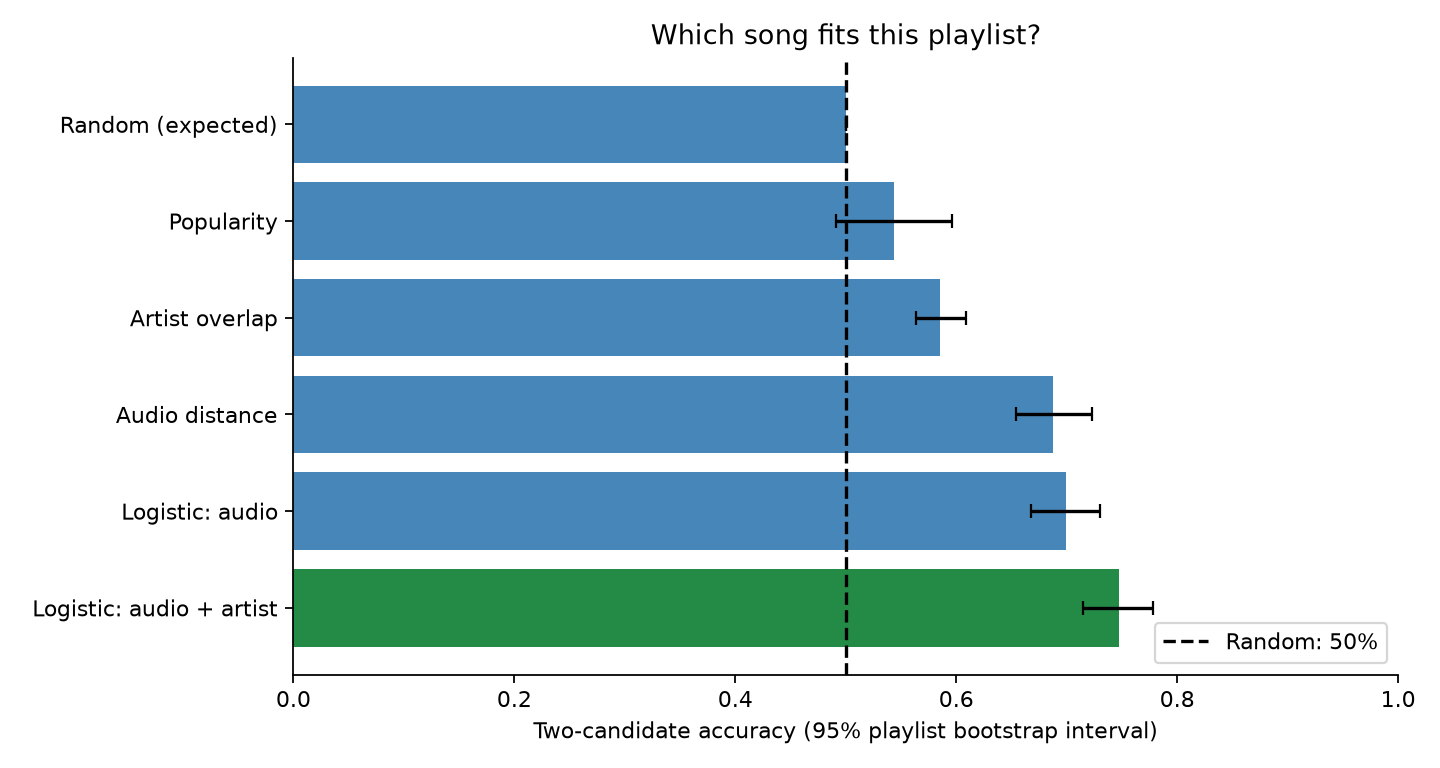

,first,second,difference,ci_low,ci_high,playlists,bootstrap_draws
0,Logistic: audio + artist,Random (expected),0.247,0.215,0.278,100,10000
1,Logistic: audio + artist,Audio distance,0.059,0.034,0.085,100,10000
2,Logistic: audio + artist,Logistic: audio,0.048,0.028,0.070,100,10000


In [13]:
results = run_experiment(data)
summary = results['summary']
display(pd.Series(summary['query_counts'], name='queries').to_frame())
display(results['grid'])
print('Validation-selected primary model:', summary['selection']['primary_model'])
display(results['metrics'].style.format({'accuracy': '{:.1%}', 'ci_low': '{:.1%}',
                                        'ci_high': '{:.1%}', 'tie_fraction': '{:.1%}'}))
display(Image(filename=str(OUT / 'accuracy.png')))
display(pd.DataFrame(summary['comparisons']))

In [14]:
primary = summary['selection']['primary_model']
row = results['metrics'].set_index('model').loc[primary]
baseline = results['metrics'].set_index('model').loc['Audio distance']
comparison = summary['comparisons'][1]
gain = ('The interval supports an improvement over the audio rule.' if comparison['ci_low'] > 0
        else 'The interval does not establish an improvement over the audio rule.'
        if comparison['ci_high'] >= 0 else 'The audio rule performs better in this comparison.')
display(Markdown(f"""**Measured result.** The validation-selected **{primary}** scores
**{row['accuracy']:.1%}** on held-out playlists (95% playlist-bootstrap interval:
{row['ci_low']:.1%}–{row['ci_high']:.1%}). Random guessing scores 50% in expectation.
The simple audio-distance rule scores **{baseline['accuracy']:.1%}**.
The learned model's paired difference from that rule is **{comparison['difference']*100:.1f}
percentage points**, with interval [{comparison['ci_low']*100:.1f}, {comparison['ci_high']*100:.1f}].
{gain}"""))
display(results['subgroups'])
display(results['coefficients'].query('model == @primary').sort_values('coefficient', ascending=False))

**Measured result.** The validation-selected **Logistic: audio + artist** scores
**74.7%** on held-out playlists (95% playlist-bootstrap interval:
71.5%–77.8%). Random guessing scores 50% in expectation.
The simple audio-distance rule scores **68.8%**.
The learned model's paired difference from that rule is **5.9
percentage points**, with interval [3.4, 8.5].
The interval supports an improvement over the audio rule.

,model,member_seen_in_training,accuracy,playlists_with_queries
0,Artist overlap,False,0.591,91
1,Artist overlap,True,0.580,94
2,Audio distance,False,0.726,91
3,Audio distance,True,0.678,94
4,Logistic: audio,False,0.733,91
5,Logistic: audio,True,0.715,94
6,Logistic: audio + artist,False,0.784,91
7,Logistic: audio + artist,True,0.746,94
8,Popularity,False,0.075,91
9,Popularity,True,0.836,94


,model,feature,coefficient
22,Logistic: audio + artist,artist_fraction,1.720
21,Logistic: audio + artist,nearest_audio,0.419
11,Logistic: audio + artist,closeness_danceability,0.367
18,Logistic: audio + artist,closeness_valence,0.331
12,Logistic: audio + artist,closeness_energy,0.314
15,Logistic: audio + artist,closeness_acousticness,0.306
13,Logistic: audio + artist,closeness_loudness,0.277
16,Logistic: audio + artist,closeness_instrumentalness,0.256
14,Logistic: audio + artist,closeness_speechiness,0.254
20,Logistic: audio + artist,closeness_duration_ms,0.124


The subgroup table separates queries whose hidden member appeared in a training playlist
from queries whose member did not. Within each subgroup, accuracy first averages within
playlist and then across playlists that have such queries. These are descriptive checks;
they do not select another model. Coefficients use one standard deviation of training
pair differences; correlated features can share or reverse weights.

In [15]:
# Show the first test example, selected by playlist/query ID rather than outcome.
q = results['queries']['test'].sort_values(['pid', 'query']).iloc[0]
seed_items = q[[f'h{i}' for i in range(5)]].to_numpy(dtype=int)
display(data['tracks'].iloc[seed_items][['track_name', 'artist_name']].assign(role='Context'))
example = data['tracks'].iloc[[int(q.candidate_a), int(q.candidate_b)]][['track_name', 'artist_name']].copy()
example.index = ['A', 'B']
example['actual_member'] = [bool(q.label), not bool(q.label)]
display(example)
details = results['details']
prediction = details[(details.model == primary) & (details.pid == q['pid']) &
                     (details['query'] == q['query'])]
score = float(prediction.score_a_minus_b.iloc[0])
print('Model chooses:', 'A' if score > 0 else 'B' if score < 0 else 'Tie: fair coin')

,track_name,artist_name,role
17077,What a Girl Wants,Pia Mia,Context
29851,Search Party - JayKode Remix,Sam Bruno,Context
17470,BLK CLD,XYLØ,Context
25328,Temple - Niko The Kid Remix,Parson James,Context
29441,You Don't Own Me,Grace,Context


,track_name,artist_name,actual_member
A,Nothing But Trouble - Instagram Models,Lil Wayne,True
B,Lower Still,My Epic,False


Model chooses: A


In [16]:
split_sets = [set(ids) for ids in data['split'].values()]
assert all(split_sets[i].isdisjoint(split_sets[j]) for i in range(3) for j in range(i))
for split, queries in results['queries'].items():
    assert set(queries.pid) <= set(data['split'][split])
    for q in queries.itertuples(index=False):
        context = {getattr(q, f'h{i}') for i in range(5)}
        member = q.candidate_a if q.label else q.candidate_b
        outsider = q.candidate_b if q.label else q.candidate_a
        assert len(context) == 5 and member not in context
        assert context | {member} <= set(data['members'][q.pid])
        assert outsider not in data['members'][q.pid]
print('Verified: disjoint playlist splits, distinct contexts, hidden members, and true nonmembers.')
display(pd.Series(summary['environment'], name='version').to_frame())
print('Dataset SHA-256:', summary['data']['dataset_sha256'])

Verified: disjoint playlist splits, distinct contexts, hidden members, and true nonmembers.

,version
python,3.14.4
numpy,2.5.5
pandas,3.1.1
sklearn,1.9.1


Dataset SHA-256: 11533e4997668e7791c093bbcc63fb20ed820e8c4bbd80b7026fedaf1fb8d946


### 4.2 Extended comparison on identical held-out playlists
There are ten queries per eligible playlist on the primary task. Average credits within each playlist, then average those means. Resample whole playlists 10,000 times for percentile intervals. For model comparisons, resample the within-playlist difference so that the two methods always face identical choices. These intervals describe the fixed fitted models and sampled alternatives. They omit uncertainty from retraining, shared curators and trying another dataset.

,Validation,Test,Lower 95%,Upper 95%,Ties
Chance,50.0%,50.0%,50.0%,50.0%,100.0%
Popularity,51.3%,54.4%,49.0%,59.8%,16.0%
Artist overlap,58.3%,58.5%,56.4%,61.0%,82.7%
Audio distance,73.7%,68.8%,65.3%,72.4%,0.0%
Artist cosine,78.4%,81.4%,78.4%,84.4%,18.6%
Logistic · audio,74.6%,69.9%,66.8%,73.0%,0.0%
Logistic · audio + artist,78.0%,74.7%,71.5%,77.8%,0.0%
Linear SVM,77.9%,74.6%,71.4%,77.7%,0.0%
Naïve Bayes,76.2%,71.5%,68.0%,75.0%,0.0%
Hybrid logistic,88.0%,86.2%,83.4%,88.9%,0.0%


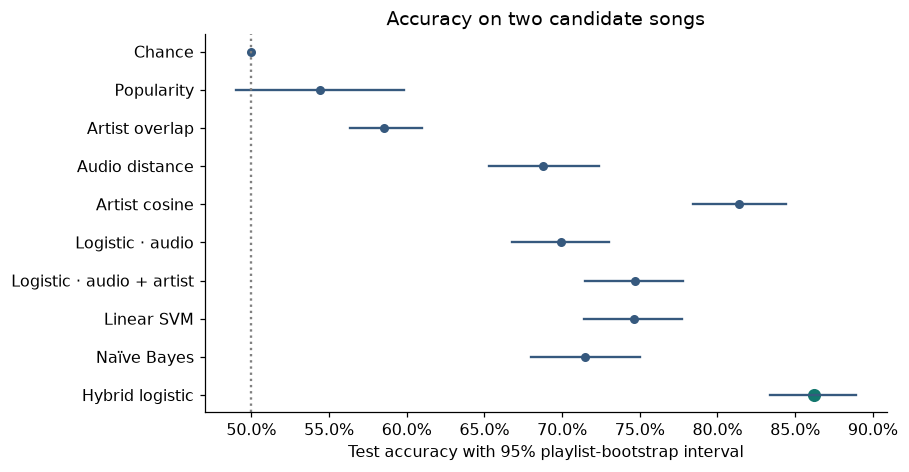

,Gain (pp),Lower 95% (pp),Upper 95% (pp)
Hybrid logistic minus Audio distance,17.400,14.100,20.700
Hybrid logistic minus Logistic · audio + artist,11.500,8.600,14.500
Hybrid logistic minus Artist cosine,4.800,2.250,7.500
Linear SVM minus Logistic · audio + artist,-0.100,-0.400,0.200
Naïve Bayes minus Logistic · audio + artist,-3.200,-5.300,-1.100


In [17]:
testing = sample_queries(test,45)
check_queries(testing)
def evaluate_extended(q):
    x = features(q,history)
    scores = rule_scores(q,x)
    for name,(kind,n) in specs.items():
        scores[name] = score_model(fitted[name],kind,x[:,:n])
        rev = score_model(fitted[name],kind,-x[:,:n])
        np.testing.assert_allclose(scores[name],-rev,atol=1e-9,rtol=1e-9)
    credits = pd.DataFrame({k:credit(v,q.y) for k,v in scores.items()},index=q.index)
    return scores,credits

def interval(values):
    v = np.asarray(values,float)
    rng = np.random.default_rng(2026)
    means = v[rng.integers(len(v),size=(10000,len(v)))].mean(axis=1)
    return np.quantile(means,[.025,.975])

scores, points = evaluate_extended(testing)
per_list = points.groupby(testing.pid).mean()
table = pd.DataFrame({'Validation':val_acc,'Test':per_list.mean(),
                      'Lower 95%':per_list.apply(lambda s:interval(s)[0]),
                      'Upper 95%':per_list.apply(lambda s:interval(s)[1]),
                      'Ties':{k:np.isclose(v,0,atol=1e-10).mean() for k,v in scores.items()}})
display(table.style.format('{:.1%}'))
fig,ax=plt.subplots(figsize=(8,4.1),layout='constrained')
for i,(name,r) in enumerate(table.iterrows()):
    ax.plot([r['Lower 95%'],r['Upper 95%']],[i,i],color=blue)
    ax.scatter(r.Test,i,color=teal if name==winner else blue,s=55 if name==winner else 23)
ax.set_yticks(np.arange(len(table)),table.index)
ax.invert_yaxis()
ax.axvline(.5,color='gray',ls=':')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title='Accuracy on two candidate songs',xlabel='Test accuracy with 95% playlist-bootstrap interval')
plt.show()
def difference(a,b):
    diff = a-b
    lo,hi = interval(diff)
    return [diff.mean()*100,lo*100,hi*100]
comparisons = [(winner,'Audio distance'),('Hybrid logistic','Logistic · audio + artist'),
               ('Hybrid logistic','Artist cosine'),('Linear SVM','Logistic · audio + artist'),('Naïve Bayes','Logistic · audio + artist')]
pairs = {f'{a} minus {b}':difference(per_list[a],per_list[b]) for a,b in comparisons}
display(pd.DataFrame.from_dict(pairs,orient='index',columns=['Gain (pp)','Lower 95% (pp)','Upper 95% (pp)']).round(2))

### 4.3 Agreement between the two implementations
The two stages must use the same split, candidates, labels and audio representation. These checks also compare the original models' per-query credit, preventing a sampling change from masquerading as a model improvement.

In [18]:
for split_name, group in [('train', train), ('validation', valid), ('test', test)]:
    np.testing.assert_array_equal(data['split'][split_name], group)
for split_name, query_frame in [('train', training), ('validation', validation), ('test', testing)]:
    old = results['queries'][split_name]
    np.testing.assert_array_equal(
        old[['pid', 'query', 'h0', 'h1', 'h2', 'h3', 'h4', 'candidate_a', 'candidate_b', 'label']].to_numpy(),
        query_frame[['pid', 'query', *context_cols, 'a', 'b', 'y']].to_numpy())
np.testing.assert_allclose(data['z'], z, atol=1e-12)
for original, extension in [('Random (expected)', 'Chance'), ('Popularity', 'Popularity'),
                            ('Artist overlap', 'Artist overlap'), ('Audio distance', 'Audio distance'),
                            ('Logistic: audio', 'Logistic · audio'),
                            ('Logistic: audio + artist', 'Logistic · audio + artist')]:
    detail = results['details'].query('model == @original').sort_values(['pid', 'query'])
    np.testing.assert_allclose(detail.correct_credit.to_numpy(), points[extension].to_numpy())
print('Verified: identical splits, queries, standardized audio and original-model test credits.')

Verified: identical splits, queries, standardized audio and original-model test credits.


### When both candidates are by the same artist
A uniformly drawn alternative can be easy to rule out by artist identity. Retain the five seeds, positive track and candidate side. Replace the outsider with a randomly chosen recording by the **hidden member’s artist** that is absent from the entire playlist. If none exists, discard that query from **both** conditions. This isolates the change in the alternative on an identical eligible subset. It also restricts the kinds of artists represented. The positive artist is used to construct this diagnostic and is never supplied as the answer to a classifier.

In [19]:
def matched_outsiders(q):
    rng = np.random.default_rng(203)
    by_artist = pd.Series(items).groupby(artist).indices
    keep, alternatives = [], []
    for i,row in q.iterrows():
        target = int(row.a if row.y else row.b)
        pool = np.setdiff1d(by_artist[artist[target]],members[row.pid],assume_unique=True)
        if len(pool):
            keep.append(i)
            alternatives.append(rng.choice(pool))
    hard = q.loc[keep].copy()
    for col,mask in [('a',hard.y.eq(0)),('b',hard.y.eq(1))]:
        hard.loc[mask,col] = np.asarray(alternatives)[mask.to_numpy()]
    return hard

hard = matched_outsiders(testing)
check_queries(hard)
assert (artist[hard.a]==artist[hard.b]).all()
hard_scores, hard_points = evaluate_extended(hard)
assert (hard_points[['Artist overlap','Artist cosine']]==.5).all().all()
matched_uni = points.loc[hard.index].groupby(hard.pid).mean()
matched_hard = hard_points.groupby(hard.pid).mean()
extended_summary = pd.DataFrame({'Uniform outsider':matched_uni.mean(),'Same-artist outsider':matched_hard.mean()})
extended_summary['Change (pp)'] = (extended_summary.iloc[:,1]-extended_summary.iloc[:,0])*100
print(f'Matched sample: {len(hard)} of {len(testing)} choices, {hard.pid.nunique()} playlists.')
display(extended_summary.style.format({'Uniform outsider':'{:.1%}','Same-artist outsider':'{:.1%}','Change (pp)':'{:+.1f}'}))
print('Same-artist primary accuracy, 95% interval (%):', np.round(100*interval(matched_hard[winner]),2))
print('Primary model, same-artist minus uniform (pp):', np.round(difference(matched_hard[winner],matched_uni[winner]),2))

Matched sample: 824 of 1000 choices, 100 playlists.


,Uniform outsider,Same-artist outsider,Change (pp)
Chance,50.0%,50.0%,+0.0
Popularity,59.1%,56.6%,-2.5
Artist overlap,57.7%,50.0%,-7.7
Audio distance,70.6%,56.0%,-14.5
Artist cosine,87.7%,50.0%,-37.7
Logistic · audio,71.2%,53.7%,-17.5
Logistic · audio + artist,75.5%,53.8%,-21.6
Linear SVM,75.5%,53.9%,-21.6
Naïve Bayes,73.1%,53.8%,-19.3
Hybrid logistic,89.2%,53.5%,-35.6


Same-artist primary accuracy, 95% interval (%): [49.38 57.68]
Primary model, same-artist minus uniform (pp): [-35.62 -40.52 -30.82]


### Read one mistake
Select the first incorrect same-artist choice in playlist and query order. This example shows a failure mode. The table above measures its broader context. Both choices could sound plausible to a listener.

In [20]:
wrong = hard_points[winner].eq(0)
idx = hard.index[wrong][0] if wrong.any() else hard.index[0]
case = hard.loc[idx]
names = catalog.reset_index()
def name(i):
    song = names.iloc[int(i)]
    return f'{song.track_name} — {song.artist_name}'
for j,c in enumerate(context_cols,1):
    print(f'{j}. {name(case[c])}')
for side in ['a','b']:
    print(f'Candidate {side.upper()}  {name(case[side])}')
margin = pd.Series(hard_scores[winner],index=hard.index).loc[idx]
print('Model choice:', 'A' if margin>0 else 'B' if margin<0 else 'Tie',
      '| Recorded member:', 'A' if case.y else 'B')
print('Playlist',int(case.pid),'· query',int(case["query"]))

1. Keeping Your Head Up - Jonas Blue Remix [Radio Edit] — Birdy
2. Watch Out — 2 Chainz
3. All We Know — Brevner
4. I Wanna Know — Alesso
5. SummerThing! — Afrojack
Candidate A  Gangsta — Kat Dahlia
Candidate B  Mirror — Kat Dahlia
Model choice: B | Recorded member: A
Playlist 1 · query 6


In the example, both choices are by Kat Dahlia. Artist overlap and co-occurrence assign them identical scores. Acoustic features break the tie in favor of *Mirror*, while the curator included *Gangsta*. A prediction error tells us which recording was absent from this playlist. The data give us no preference judgment between the songs.

## 5. Discussion of related work, findings and limits

### 5.1 Original benchmark: interpretation and related work

The measured result and confidence intervals above answer the research question directly.
Compare the learned model to both random guessing and the audio rule before claiming
that a more complex model is useful. Artist overlap may help explain shared performers,
while audio similarity remains available for recordings absent from training playlists.
The paired audio-plus-artist comparison measures the observed incremental benefit of
artist overlap rather than assuming it helps.

**How this relates to existing work.** Spotify's
[2018 playlist-continuation challenge](https://research.atspotify.com/publications/recsys-challenge-2018-automatic-music-playlist-continuation)
studied recommending tracks for existing playlists. Our task shares that motivation but
asks a narrower question: distinguish one observed member from one sampled nonmember.
Its catalogue-retrieval metrics and this notebook's two-candidate accuracy cannot be
compared numerically. The Google Drive presentation linked in Section 2 provides the
project's earlier feature-based grouping and recommendation context; it does not
validate the results of this new experiment.

**Limits that matter when explaining accuracy:**

- A randomly sampled nonmember may be easy to distinguish. Accuracy applies to this
  exact candidate sampler; it does not establish performance against carefully selected
  similar alternatives or over the entire catalogue.
- Absence from a playlist does not imply dislike. The label measures recorded membership,
  not musical quality, listener satisfaction, or whether a new recommendation is welcome.
- Random five-song contexts test playlist compatibility, not the immediate next song.
  Deduplication and context sampling intentionally discard order.
- Playlists are held out, but tracks and artists can overlap across splits. Metadata for
  all candidates is assumed available. No dates support claims about future playlists.
- Different playlist IDs could still share very similar content. The playlist split does
  not guarantee independence of curators or eliminate copied playlists.
- Ten queries per playlist share context and labels. Playlist-bootstrap intervals account
  for this clustering, conditional on the fixed split, sampled queries, and fitted model;
  they do not capture all variation from retraining or another negative sampler.
- The test split has been explored in the earlier next-song task. This is a new task and
  a fixed protocol, not a claim that the underlying data has never been inspected.

**Presentation-ready explanation:** “We show five songs from a playlist and ask our model
to choose which of two other songs was also in it. It compares how similar the songs
sound and whether they share artists. We test it on playlists excluded from training.”

The original benchmark proposed freezing its model and evaluating more similar nonmembers. Section 4 implements that follow-up as a separately reported same-artist diagnostic. It retains the original uniform-negative benchmark and compares both conditions on the same eligible subset.

### 5.2 Extended findings and comparison with published work

**What improved the model?** Adding artist co-occurrence raised accuracy from 74.7% to 86.2% on the original task, a paired improvement of 11.5 percentage points (95% interval 8.6 to 14.5). A stand-alone artist-cosine rule already achieved 81.4%. Switching the loss from logistic to squared hinge moved accuracy by −0.1 points (interval −0.4 to +0.2). Naïve Bayes scored 71.5%. Its comparison changes both the likelihood and the representation because it keeps only the direction of each difference. The results identify artist co-curation as a useful source of evidence and leave the two linear objectives effectively tied on these playlists.

**What happens when the easy clue disappears?** On the 824 eligible queries, the hybrid fell from 89.1% against uniform alternatives to 53.5% against same-artist alternatives. The paired drop was 35.6 points (95% interval for the drop 30.8 to 40.5). Artist cosine ties on every same-artist query by construction. The simple audio-distance rule reached 56.0% on those choices. For choosing between recordings by one performer, testing features such as album context or track-level co-occurrence on fresh playlists is a more direct follow-up than tuning the classifier again.

**Relation to the literature.** Chen et al. describe the 2018 Spotify challenge, where systems recommend many missing tracks and are evaluated using R-precision, NDCG and clicks. Our result supports using playlist co-occurrence as a source of evidence on this slice. The challenge's catalog-scale ranking and our sampled two-song choice have different denominators, so 86.2% cannot serve as a leaderboard comparison. [Chen et al., RecSys 2018](https://research.atspotify.com/publications/recsys-challenge-2018-automatic-music-playlist-continuation)

Vall et al. trained a song-to-playlist classifier with descriptors derived from audio, tags and listening logs. They found feature-based recommendations especially valuable when song histories were sparse. Here 28,779 recordings appear in at most one training playlist. Pooling at artist level supplies a coarser form of history and improves average accuracy. Our same-artist test exposes its resolution limit. We did not estimate their rare-song recall, so the results speak to a shared modeling problem rather than a replication of their metric. [Vall et al., 2017](https://arxiv.org/abs/1705.08283)

**Where the claim travels.** A playlist-disjoint split protects against the same playlist ID appearing in training and testing. Shared artists, related curators, covers and near-duplicate playlists can still induce dependence. Ten choices per playlist and a playlist bootstrap address repeated queries within each playlist. Dates, curator grouping and independent test slices would be needed to assess temporal drift, creator-level generalization and stability across datasets. The practical use supported here is choosing between two supplied candidates under the stated sampling conditions.